Predicting the exam score using the Simple linear regression

In [1]:
import pandas as pd


In [27]:
data=pd.read_csv(r'.\archive\student_exam_performance.csv')

In [29]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  str    
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   education_level             100000 non-null  str    
 4   school_type                 100000 non-null  str    
 5   family_income               100000 non-null  str    
 6   parent_education            93474 non-null   str    
 7   urban_rural                 100000 non-null  str    
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  str    
 13  study_hours_per_day       

In [33]:
data=data.drop(columns='student_id')
data.duplicated().sum()

np.int64(0)

In [44]:
missed=data.isna().sum()[data.isna().sum()>0]
missed

parent_education         6526
previous_gpa             7793
attendance_percentage    9863
notes_quality            8407
sleep_quality            6994
device_availability      2965
time_management_score    9613
dtype: int64

In [53]:
missed_df=pd.DataFrame(missed,columns=['features'])
missed_df=missed_df.reset_index()
missed_df['percent']=(missed_df['features'] / len(data.index))*100

In [54]:
missed_df

,index,features,percent
0,parent_education,6526,6.526
1,previous_gpa,7793,7.793
2,attendance_percentage,9863,9.863
3,notes_quality,8407,8.407
4,sleep_quality,6994,6.994
5,device_availability,2965,2.965
6,time_management_score,9613,9.613


In [ ]:
x=data[['previous_exam_score']]   # Taking this feature in a 2D because the matrix feature matrix should be 2D
y=data['exam_score']
x.shape

(100000, 1)

In [132]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

(80000, 1) (20000, 1) (80000,) (20000,)


In [ ]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.69]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['previous_exam_score']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.11
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [136]:
print(model.coef_,model.intercept_)

[0.68758962] 14.109659953679738


In [137]:
pred_on_x_test=model.predict(x_test)

In [140]:
from sklearn.metrics import r2_score,mean_squared_error,root_mean_squared_error

print('mean_squared_error',mean_squared_error(y_test,pred_on_x_test))
print('root_mean_squared_error',root_mean_squared_error(y_test,pred_on_x_test))
print('r2_score',r2_score(y_test,pred_on_x_test))

mean_squared_error 185.99043296917776
root_mean_squared_error 13.6378309481082
r2_score 0.2518079559604671


In [145]:
model.score(x_train, y_train),model.score(x_test,y_test)

(0.24263560288619512, 0.2518079559604671)

In [144]:
model.score(x_test,y_test)

0.2518079559604671

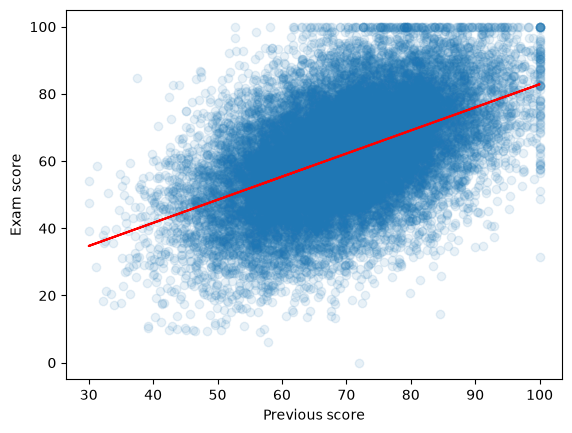

In [147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


plt.scatter(x_test, y_test, alpha=0.1)
plt.plot(x_test, pred_on_x_test, color='red')
plt.xlabel('Previous score')
plt.ylabel('Exam score')
plt.show()

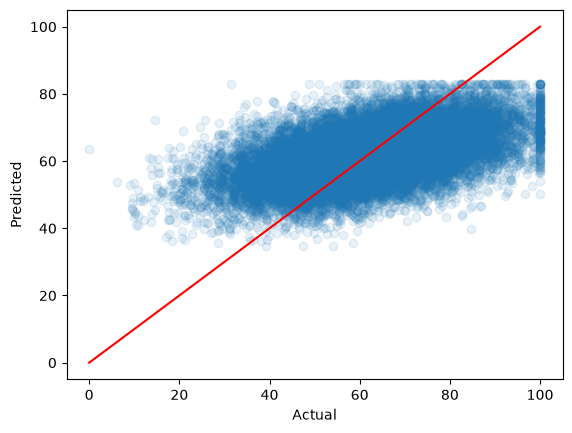

In [148]:
plt.scatter(y_test, pred_on_x_test, alpha=0.1)
plt.plot([0, 100], [0, 100], color='red')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

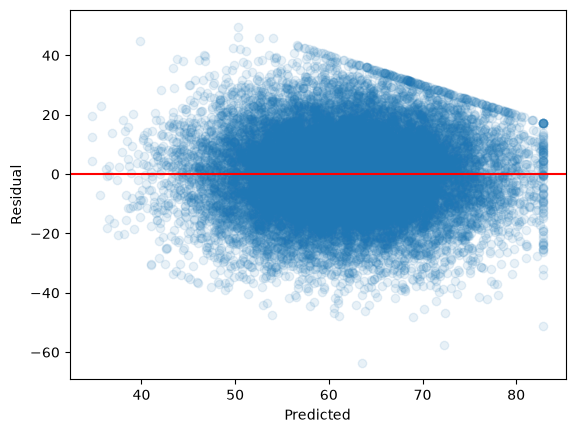

In [149]:
residuals = y_test - pred_on_x_test

plt.scatter(pred_on_x_test, residuals, alpha=0.1)
plt.axhline(0, color='red')
plt.xlabel('Predicted')
plt.ylabel('Residual')
plt.show()

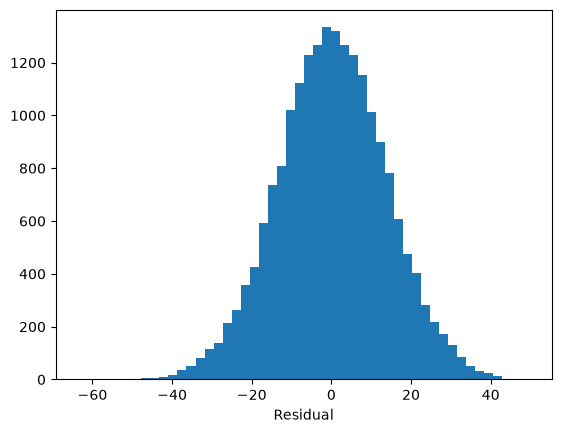

In [150]:
plt.hist(residuals, bins=50)
plt.xlabel('Residual')
plt.show()